In [ ]:
"""
Bridge Posting Prediction Project - Complete Pipeline
Analysis of Truck Traffic, Movable Bridges, and Operational Risk in U.S. Bridges
Using National Bridge Inventory Data 2024-2025
"""

# ===========================
# SECTION 1: Environment Setup
# ===========================
import sys
if 'google.colab' in sys.modules:
    !apt-get -qq update > /dev/null 2>&1
    !apt-get -qq install -y openjdk-17-jdk-headless > /dev/null 2>&1
    !pip -q install pyspark==3.5.1
    import os
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"

from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import DoubleType, IntegerType
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    VectorAssembler, StandardScaler, StringIndexer, OneHotEncoder, Imputer
)
from pyspark.ml.classification import LogisticRegression, DecisionTreeClassifier, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("\n Libraries imported successfully")


 Libraries imported successfully


In [ ]:
# ===========================
# SECTION 2: Spark Session Init
# ===========================
spark = (SparkSession.builder
         .appName("AIT614_Bridge_Analysis")
         .config("spark.driver.memory", "6g")
         .config("spark.sql.shuffle.partitions", "64")
         .config("spark.sql.adaptive.enabled", "true")
         .getOrCreate())

print(f"\n Spark Version: {spark.version}")
print(f" Spark UI URL: {spark.sparkContext.uiWebUrl}")


 Spark Version: 3.5.1
 Spark UI URL: http://f6a11e65805b:4040


In [ ]:
# ===========================
# SECTION 3: Data Loading
# ===========================
DATA_PATH = "/content/CleanedBridgeDataset_2024and2025.csv"
df_raw = (spark.read.option("header", True)
                 .option("inferSchema", True)
                 .csv(DATA_PATH))

print(f"\nData loaded: {df_raw.count():,} rows, {len(df_raw.columns)} columns")
df_raw.printSchema()
df_raw.show(5, truncate=False)


Data loaded: 957,758 rows, 15 columns
root
 |-- Year: integer (nullable = true)
 |-- 1 - State Code: integer (nullable = true)
 |-- 1 - State Name: string (nullable = true)
 |-- 8 - Structure Number: string (nullable = true)
 |-- 2025 NBI Structure Number: string (nullable = true)
 |-- 22 - Owner Agency: string (nullable = true)
 |-- 27 - Year Built: integer (nullable = true)
 |-- 43A - Main Span Material: string (nullable = true)
 |-- 43B - Main Span Design: string (nullable = true)
 |-- 48 - Length of Maximum Span (ft.): double (nullable = true)
 |-- 29 - Average Daily Traffic: double (nullable = true)
 |-- 109 - Average Daily Truck Traffic (Percent ADT): double (nullable = true)
 |-- 31 - Design Load Descriptor: string (nullable = true)
 |-- 30 - Year of Average Daily Traffic: integer (nullable = true)
 |-- 70 - Bridge Posting Code: integer (nullable = true)

+----+--------------+--------------+--------------------+-------------------------+-------------------------------+---------

In [ ]:
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType, IntegerType
from pyspark.ml.feature import Imputer

# ===============================
# STEP 4: FEATURE ENGINEERING
# ===============================
def prepare_features(df):
    # Column detection
    def safe_match(df, keyword):
        """Find a column containing the keyword (case-insensitive). Return longest match if multiple."""
        matches = [c for c in df.columns if keyword.lower() in c.lower()]
        if not matches:
            print(f"No match for '{keyword}'")
            return None
        if len(matches) > 1:
            print(f"⚠️ WARNING: Multiple matches for '{keyword}': {matches}")
            matches = sorted(matches, key=len, reverse=True)
        return matches[0]

    # Detect and map columns
    state_col      = safe_match(df, "State Name")
    year_built_col = safe_match(df, "Year Built")
    span_col       = safe_match(df, "Length of Maximum Span")
    truck_col      = safe_match(df, "Average Daily Truck Traffic")
    posting_col    = safe_match(df, "Bridge Posting Code")
    material_col   = safe_match(df, "Main Span Material")
    design_col     = safe_match(df, "Main Span Design")
    structure_col  = safe_match(df, "Structure Number")

    print("\n=== FINAL COLUMN MAPPINGS ===")
    print(f"State Name       → {state_col}")
    print(f"Year Built       → {year_built_col}")
    print(f"Span Length      → {span_col}")
    print(f"Truck %          → {truck_col}")
    print(f"Posting Code     → {posting_col}")
    print(f"Main Material    → {material_col}")
    print(f"Main Design      → {design_col}")
    print(f"Structure Number → {structure_col}")

    # rename columns
    df = df.withColumnRenamed(state_col, "state_name") \
           .withColumnRenamed(year_built_col, "year_built_raw") \
           .withColumnRenamed(span_col, "span_len_raw") \
           .withColumnRenamed(truck_col, "truck_pct_raw") \
           .withColumnRenamed(posting_col, "posting_code_raw") \
           .withColumnRenamed(material_col, "main_material") \
           .withColumnRenamed(design_col, "main_design") \
           .withColumnRenamed(structure_col, "structure_num")

    # cleaning for main design
    df = df.filter(~F.col("main_design").rlike("^[0-9]+$"))

    # Numeric features
    df = df.withColumn("year_built", F.col("year_built_raw").cast(DoubleType())) \
           .withColumn("bridge_age", F.lit(2025) - F.col("year_built")) \
           .withColumn("span_len", F.col("span_len_raw").cast(DoubleType())) \
           .withColumn("truck_pct", F.col("truck_pct_raw").cast(DoubleType()))

    # INTERACTION FEATURES
    df = df.withColumn("age_truck_interaction", F.col("bridge_age") * F.col("truck_pct")) \
           .withColumn("span_truck_interaction", F.col("span_len") * F.col("truck_pct")) \
           .withColumn("age_span_interaction", F.col("bridge_age") * F.col("span_len"))

    # POLYNOMIAL FEATURES
    df = df.withColumn("bridge_age_squared", F.pow(F.col("bridge_age"), 2)) \
           .withColumn("span_len_log", F.log1p(F.col("span_len"))) \
           .withColumn("truck_pct_squared", F.pow(F.col("truck_pct"), 2))

    # 7. CATEGORICAL BINS
    df = df.withColumn("age_category",
                       F.when(F.col("bridge_age") <= 20, "new")
                        .when(F.col("bridge_age") <= 50, "middle")
                        .when(F.col("bridge_age") <= 75, "old")
                        .otherwise("very_old")) \
           .withColumn("truck_category",
                       F.when(F.col("truck_pct") <= 5, "low")
                        .when(F.col("truck_pct") <= 10, "moderate")
                        .when(F.col("truck_pct") <= 15, "high")
                        .otherwise("very_high"))

    # TARGET VARIABLE
    df = df.withColumn("is_posted",
                       F.when(F.col("posting_code_raw").cast("string") == "5", 0)
                        .otherwise(1).cast(IntegerType()))

    # MOVABLE BRIDGES
    df = df.withColumn(
        "is_movable",
        F.when(
            F.lower(F.regexp_replace(F.col("main_design").cast("string"), "[^a-zA-Z ]", " "))
             .rlike("bascule|swing|lift|movable|draw"), 1
        ).otherwise(0).cast(IntegerType())
    )

    # FILL MISSING CATEGORICAL VALUES
    cat_cols = ["main_material", "main_design", "age_category", "truck_category", "state_name"]
    df = df.fillna({c: "Unknown" for c in cat_cols})

    # SELECT FINAL COLUMNS
    selected_cols = [
        "structure_num", "state_name",
        "bridge_age", "span_len", "truck_pct",
        "age_truck_interaction", "span_truck_interaction", "age_span_interaction",
        "bridge_age_squared", "span_len_log", "truck_pct_squared",
        "main_material", "main_design", "age_category", "truck_category",
        "is_movable", "is_posted"
    ]

    return df.select(*selected_cols).cache()

df_processed = prepare_features(df_raw)

⚠️ WARNING: Multiple matches for 'Structure Number': ['8 - Structure Number', '2025 NBI Structure Number']

=== FINAL COLUMN MAPPINGS ===
State Name       → 1 - State Name
Year Built       → 27 - Year Built
Span Length      → 48 - Length of Maximum Span (ft.)
Truck %          → 109 - Average Daily Truck Traffic (Percent ADT)
Posting Code     → 70 - Bridge Posting Code
Main Material    → 43A - Main Span Material
Main Design      → 43B - Main Span Design
Structure Number → 2025 NBI Structure Number


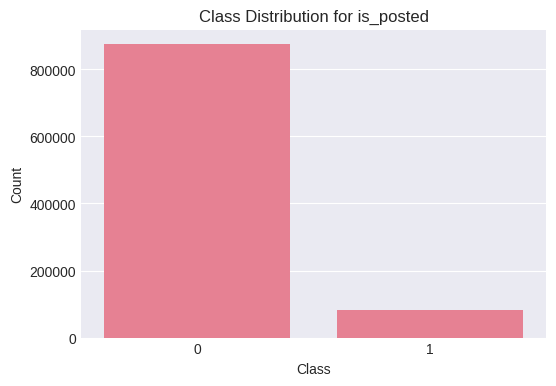

In [ ]:
# Class Imbalance
class_counts = df_processed.groupBy('is_posted').count().toPandas()
# Plot
plt.figure(figsize=(6,4))
sns.barplot(x='is_posted', y='count', data=class_counts)
plt.title('Class Distribution for is_posted')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

In [ ]:
# ===========================
# SECTION 4.1: Impute Numerical Features
# ===========================
numerical_cols_to_impute = [
    'bridge_age', 'span_len', 'truck_pct',
    'age_truck_interaction', 'span_truck_interaction', 'age_span_interaction',
    'bridge_age_squared', 'span_len_log', 'truck_pct_squared'
]
imputed_cols = [col + '_imp' for col in numerical_cols_to_impute]

imputer = Imputer(
    inputCols=numerical_cols_to_impute,
    outputCols=imputed_cols,
    strategy='mean' # You can choose 'mean', 'median', or 'mode'
)

model = imputer.fit(df_processed)
df_imputed = model.transform(df_processed)

print(f"\nNumerical features imputed. DataFrame now has {df_imputed.count():,} rows and {len(df_imputed.columns)} columns.")
# Verify that there are no NaNs in the imputed columns
df_imputed.select(*imputed_cols).summary("count").show()

# Adding a check to ensure df_imputed is indeed defined
if 'df_imputed' in locals() or 'df_imputed' in globals():
    print("\ndf_imputed is successfully defined after imputation.")
else:
    print("\nWARNING: df_imputed was NOT defined after imputation. There might be a deeper issue.")


Numerical features imputed. DataFrame now has 956,254 rows and 26 columns.
+-------+--------------+------------+-------------+-------------------------+--------------------------+------------------------+----------------------+----------------+---------------------+
|summary|bridge_age_imp|span_len_imp|truck_pct_imp|age_truck_interaction_imp|span_truck_interaction_imp|age_span_interaction_imp|bridge_age_squared_imp|span_len_log_imp|truck_pct_squared_imp|
+-------+--------------+------------+-------------+-------------------------+--------------------------+------------------------+----------------------+----------------+---------------------+
|  count|        956254|      956254|       956254|                   956254|                    956254|                  956254|                956254|          956254|               956254|
+-------+--------------+------------+-------------+-------------------------+--------------------------+------------------------+----------------------+----

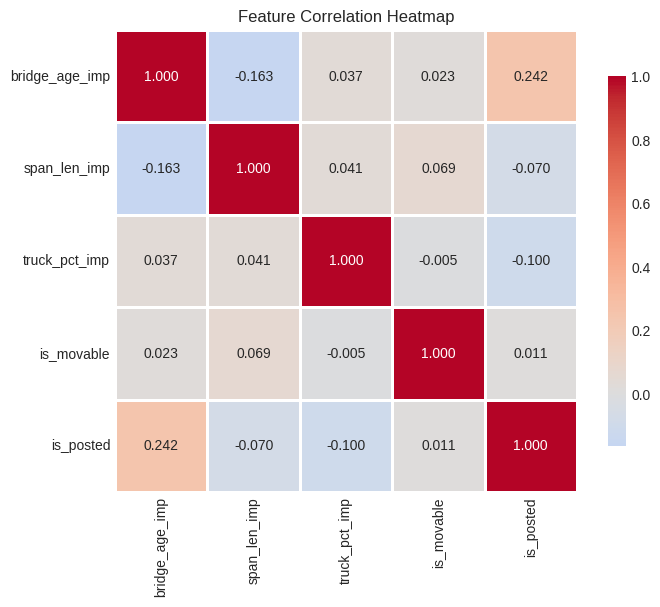

In [ ]:
# ===========================
# SECTION 5: Exploratory Data Analysis (Correlation Only)
# ===========================

from pyspark.ml.feature import VectorAssembler
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Select relevant features for correlation analysis
corr_features = ['bridge_age_imp', 'span_len_imp', 'truck_pct_imp', 'is_movable', 'is_posted']
assembler_corr = VectorAssembler(inputCols=corr_features, outputCol='features_corr')
df_corr = assembler_corr.transform(df_imputed).select('features_corr')

from pyspark.ml.stat import Correlation
corr_matrix = Correlation.corr(df_corr, 'features_corr').head()[0].toArray()
corr_df = pd.DataFrame(corr_matrix, columns=corr_features, index=corr_features)

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_df, annot=True, fmt='.3f', cmap='coolwarm', center=0,
    square=True, linewidths=1, cbar_kws={"shrink": 0.8}
)
plt.title('Feature Correlation Heatmap')
plt.show()

In [ ]:
# ===========================
# SECTION 6: Class Imbalance Handling
# ===========================
def calculate_class_weights(df, label_col):
    counts = df.groupBy(label_col).count().collect()
    counts_dict = {row[label_col]: row['count'] for row in counts}
    total = sum(counts_dict.values())
    n_classes = len(counts_dict)
    weights = {cls: total / (n_classes * count) for cls, count in counts_dict.items()}
    return weights

def add_sample_weights(df, label_col):
    weights = calculate_class_weights(df, label_col)
    weight_expr = None
    for cls, w in weights.items():
        if weight_expr is None:
            weight_expr = F.when(F.col(label_col) == cls, F.lit(w))
        else:
            weight_expr = weight_expr.when(F.col(label_col) == cls, F.lit(w))
    df = df.withColumn('sample_weight', weight_expr.otherwise(F.lit(1.0)))
    return df

# Calculate and add weights for 'is_posted'
df_imputed = add_sample_weights(df_imputed, 'is_posted')

In [ ]:
# ===========================
# SECTION 6B: Class Imbalance Reporting
# ===========================

from pyspark.sql import functions as F

print("\n================ CLASS IMBALANCE REPORT ================\n")

# 1. Show raw class counts
class_counts_df = df_imputed.groupBy("is_posted").count().orderBy("is_posted")
class_counts = class_counts_df.collect()

print("Class counts:")
for row in class_counts:
    print(f"  Class {row['is_posted']}: {row['count']:,}")

# 2. Compute imbalance ratio
count_0 = next(row['count'] for row in class_counts if row['is_posted'] == 0)
count_1 = next(row['count'] for row in class_counts if row['is_posted'] == 1)

imb_ratio = count_1 / count_0
print(f"\nImbalance Ratio (Posted : Not Posted) = {count_1:,} / {count_0:,} = {imb_ratio:.4f}")

# 3. Show sample weights computed earlier
weights = calculate_class_weights(df_imputed, "is_posted")

print("\nCalculated class weights:")
for cls, w in weights.items():
    print(f"  Class {cls} weight: {w:.6f}")

# 4. Verify weight distribution on the dataframe
print("\nTop 10 rows with sample weights:")
df_imputed.select("is_posted", "sample_weight").show(10)

# 5. Summarize weight statistics
print("\nSample weight summary:")
df_imputed.select("sample_weight").summary().show()


================ CLASS IMBALANCE REPORT ================

Class counts:
  Class 0: 874,550
  Class 1: 81,704

Imbalance Ratio (Posted : Not Posted) = 81,704 / 874,550 = 0.0934

Calculated class weights:
  Class 0 weight: 0.546712
  Class 1 weight: 5.851941

Top 10 rows with sample weights:
+---------+------------------+
|is_posted|     sample_weight|
+---------+------------------+
|        0|0.5467120233262821|
|        0|0.5467120233262821|
|        0|0.5467120233262821|
|        0|0.5467120233262821|
|        0|0.5467120233262821|
|        0|0.5467120233262821|
|        0|0.5467120233262821|
|        0|0.5467120233262821|
|        0|0.5467120233262821|
|        0|0.5467120233262821|
+---------+------------------+
only showing top 10 rows


Sample weight summary:
+-------+------------------+
|summary|     sample_weight|
+-------+------------------+
|  count|            956254|
|   mean|0.9999999999998078|
| stddev|1.4830134484627102|
|    min|0.5467120233262821|
|    25%|0.5467120233

In [ ]:
# ===========================
# SECTION 7: Train-Test Split
# ===========================
train_data, test_data = df_imputed.randomSplit([0.8, 0.2], seed=42)
train_data = train_data.cache()
test_data = test_data.cache()
print(f"\nData split into train ({train_data.count():,}) and test ({test_data.count():,}) sets.")


Data split into train (765,165) and test (191,089) sets.


In [ ]:
# ===========================
# SECTION 8: Feature Lists by Question
# ===========================
RQ1_NUMERIC_FEATURES = ['bridge_age_imp', 'span_len_imp', 'truck_pct_imp', 'is_movable']
RQ1_CATEGORICAL_FEATURES = ['main_material', 'main_design', 'state_name']

RQ2_NUMERIC_FEATURES = RQ1_NUMERIC_FEATURES + [
    'age_truck_interaction_imp',
    'span_truck_interaction_imp',
    'age_span_interaction_imp',
    'bridge_age_squared_imp',
    'span_len_log_imp',
    'truck_pct_squared_imp'
]
RQ2_CATEGORICAL_FEATURES = RQ1_CATEGORICAL_FEATURES + ['age_category', 'truck_category']

In [ ]:
import sys
if 'google.colab' in sys.modules:
    !apt-get -qq update > /dev/null 2>&1
    !apt-get -qq install -y openjdk-17-jdk-headless > /dev/null 2>&1
    !pip -q install pyspark==3.5.1
    import os
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"

from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import DoubleType, IntegerType
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    VectorAssembler, StandardScaler, StringIndexer, OneHotEncoder, Imputer
)
from pyspark.ml.classification import LogisticRegression, DecisionTreeClassifier, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("\n Libraries imported successfully")

# ===========================
# SECTION 9: Pipeline Builders
# ===========================
def build_logistic_regression_pipeline(numeric_features, categorical_features, label_col, pipeline_name):
    stages = []
    indexed_cols = []
    for cat_col in categorical_features:
        stages.append(StringIndexer(inputCol=cat_col, outputCol=f"{cat_col}_idx", handleInvalid='keep'))
        indexed_cols.append(f"{cat_col}_idx")
    stages.append(OneHotEncoder(inputCols=indexed_cols,
                                outputCols=[f"{col}_ohe" for col in indexed_cols], dropLast=False))
    assembler = VectorAssembler(inputCols=numeric_features + [f"{col}_ohe" for col in indexed_cols], outputCol='features_raw', handleInvalid='skip')
    stages.append(assembler)
    stages.append(StandardScaler(inputCol='features_raw', outputCol='features', withMean=True, withStd=True))
    lr = LogisticRegression(featuresCol='features', labelCol=label_col, weightCol='sample_weight', maxIter=100, regParam=0.01, elasticNetParam=0.0)
    stages.append(lr)
    return Pipeline(stages=stages)

def build_decision_tree_pipeline(numeric_features, categorical_features, label_col, pipeline_name):
    stages = []
    indexed_cols = []
    for cat_col in categorical_features:
        stages.append(StringIndexer(inputCol=cat_col, outputCol=f"{cat_col}_idx", handleInvalid='keep'))
        indexed_cols.append(f"{cat_col}_idx")
    assembler = VectorAssembler(inputCols=numeric_features + indexed_cols, outputCol='features', handleInvalid='skip')
    stages.append(assembler)
    dt = DecisionTreeClassifier(featuresCol='features', labelCol=label_col, weightCol='sample_weight', maxDepth=10, minInstancesPerNode=100, maxBins=150, impurity='gini', seed=42)
    stages.append(dt)
    return Pipeline(stages=stages)


 Libraries imported successfully


In [ ]:
# ===========================
# XGBoost Pipeline Builder
# ===========================
from xgboost.spark import SparkXGBClassifier

def build_xgb_pipeline(numeric_features, categorical_features, label_col, pipeline_name):
    stages = []

    # 1. Index categorical columns
    indexed_cols = []
    for cat in categorical_features:
        idx_col = f"{cat}_idx"
        stages.append(StringIndexer(inputCol=cat, outputCol=idx_col, handleInvalid="keep"))
        indexed_cols.append(idx_col)

    # 2. Assemble features
    assembler = VectorAssembler(
        inputCols=numeric_features + indexed_cols,
        outputCol="features",
        handleInvalid="skip"
    )
    stages.append(assembler)

    # 3. XGBoost Classifier
    xgb = SparkXGBClassifier(
        label_col=label_col,
        features_col="features",
        weight_col="sample_weight", # Changed from weightCol to weight_col
        numWorkers=4,
        missing=-999,
        # Removed objective="binary:logistic" as it's not allowed
        maxDepth=6,
        eta=0.1,
        numRound=60,
        subsample=0.8,
        colsampleByTree=0.8
    )
    stages.append(xgb)

    return Pipeline(stages=stages)

In [ ]:
# ===========================
# SECTION 10: Training and Evaluation
# ===========================
def train_and_evaluate_model(pipeline, train_df, test_df, label_col, model_name):
    import time
    print(f"\n{'='*80}\nTraining: {model_name}\n{'='*80}")
    start_time = time.time()
    model = pipeline.fit(train_df)
    train_time = time.time() - start_time
    predictions = model.transform(test_df).cache()

    # Metrics
    roc_eval = BinaryClassificationEvaluator(labelCol=label_col, metricName='areaUnderROC')
    pr_eval = BinaryClassificationEvaluator(labelCol=label_col, metricName='areaUnderPR')
    acc_eval = MulticlassClassificationEvaluator(labelCol=label_col, metricName='accuracy')
    f1_eval = MulticlassClassificationEvaluator(labelCol=label_col, metricName='f1')
    prec_eval = MulticlassClassificationEvaluator(labelCol=label_col, metricName='weightedPrecision')
    rec_eval = MulticlassClassificationEvaluator(labelCol=label_col, metricName='weightedRecall')

    roc_auc = roc_eval.evaluate(predictions)
    pr_auc = pr_eval.evaluate(predictions)
    accuracy = acc_eval.evaluate(predictions)
    f1 = f1_eval.evaluate(predictions)
    precision = prec_eval.evaluate(predictions)
    recall = rec_eval.evaluate(predictions)

    cm = predictions.groupBy(label_col, 'prediction').count().toPandas().pivot(index=label_col, columns='prediction', values='count').fillna(0)
    tn = cm.loc[0, 0.0] if (0 in cm.index and 0.0 in cm.columns) else 0
    fp = cm.loc[0, 1.0] if (0 in cm.index and 1.0 in cm.columns) else 0
    fn = cm.loc[1, 0.0] if (1 in cm.index and 0.0 in cm.columns) else 0
    tp = cm.loc[1, 1.0] if (1 in cm.index and 1.0 in cm.columns) else 0

    pos_prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    pos_rec = tp / (tp + fn) if (tp + fn) > 0 else 0
    pos_f1 = 2 * pos_prec * pos_rec / (pos_prec + pos_rec) if (pos_prec + pos_rec) > 0 else 0

    print(f"\nAccuracy: {accuracy:.4f}, F1 Score: {f1:.4f}, ROC AUC: {roc_auc:.4f}, PR AUC: {pr_auc:.4f}")
    print(f"Positive Class Precision: {pos_prec:.4f}, Recall: {pos_rec:.4f}, F1: {pos_f1:.4f}")
    print(f"Confusion Matrix (TN FP FN TP): {tn} {fp} {fn} {tp}")
    print(f"Training Time: {train_time:.1f} seconds")

    metrics = {
        'roc_auc': roc_auc,
        'pr_auc': pr_auc,
        'accuracy': accuracy,
        'f1': f1,
        'precision': precision,
        'recall': recall,
        'pos_precision': pos_prec,
        'pos_recall': pos_rec,
        'pos_f1': pos_f1,
        'confusion_matrix': {'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp},
        'train_time': train_time
    }
    return model, predictions, metrics

In [ ]:
# ===========================
# SECTION 11: RQ1 Inferential Analysis
# ===========================
print("\n--- RQ1: Inferential Logistic Regression ---")
train_rq1 = add_sample_weights(train_data, 'is_posted')
pipeline_rq1_lr = build_logistic_regression_pipeline(RQ1_NUMERIC_FEATURES, RQ1_CATEGORICAL_FEATURES, 'is_posted', 'RQ1_LR')
model_rq1_lr, pred_rq1_lr, metrics_rq1_lr = train_and_evaluate_model(pipeline_rq1_lr, train_rq1, test_data, 'is_posted', 'RQ1 Logistic Regression')

lr_model = model_rq1_lr.stages[-1]
coefficients = lr_model.coefficients.toArray()
feature_names = RQ1_NUMERIC_FEATURES + [f"{cat}_ohe" for cat in RQ1_CATEGORICAL_FEATURES]  # Approximation for illustration

print("\nRQ1 Coefficients (Numeric Features):")
for i, feat in enumerate(RQ1_NUMERIC_FEATURES):
    coef = coefficients[i]
    odds_ratio = np.exp(coef)
    print(f"{feat:<20} Coef: {coef:.4f} Odds Ratio: {odds_ratio:.4f}")

# Prepare base LR results for summary
rq1_lr_base_results = [{
    'name': 'Base LR',
    'params': {'maxIter': 100, 'regParam': 0.01, 'elasticNetParam': 0.0}, # Default params from build_logistic_regression_pipeline
    'metrics': metrics_rq1_lr
}]



--- RQ1: Inferential Logistic Regression ---

Training: RQ1 Logistic Regression

Accuracy: 0.8192, F1 Score: 0.8540, ROC AUC: 0.9062, PR AUC: 0.5059
Positive Class Precision: 0.3012, Recall: 0.8506, F1: 0.4449
Confusion Matrix (TN FP FN TP): 142704 32113 2431 13841
Training Time: 17.2 seconds

RQ1 Coefficients (Numeric Features):
bridge_age_imp       Coef: 0.7731 Odds Ratio: 2.1665
span_len_imp         Coef: -0.6562 Odds Ratio: 0.5188
truck_pct_imp        Coef: -0.3845 Odds Ratio: 0.6808
is_movable           Coef: 0.0232 Odds Ratio: 1.0234


In [ ]:
# ===========================
# Manual Hyperparameter Tuning for Logistic Regression (RQ1)
# ===========================

from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
import time

# Define manual hyperparameter combinations
param_combinations = [
    {'regParam': 0.001, 'elasticNetParam': 0.0, 'maxIter': 50},
    {'regParam': 0.01, 'elasticNetParam': 0.0, 'maxIter': 100},
    {'regParam': 0.05, 'elasticNetParam': 0.5, 'maxIter': 100},
    {'regParam': 0.1, 'elasticNetParam': 1.0, 'maxIter': 200},
    {'regParam': 0.01, 'elasticNetParam': 0.5, 'maxIter': 200}
]

# Evaluators
roc_evaluator = BinaryClassificationEvaluator(labelCol='is_posted', metricName='areaUnderROC')
accuracy_evaluator = MulticlassClassificationEvaluator(labelCol='is_posted', metricName='accuracy')
f1_evaluator = MulticlassClassificationEvaluator(labelCol='is_posted', metricName='f1')
pr_evaluator = BinaryClassificationEvaluator(labelCol='is_posted', metricName='areaUnderPR')
prec_evaluator = MulticlassClassificationEvaluator(labelCol='is_posted', metricName='weightedPrecision')
rec_evaluator = MulticlassClassificationEvaluator(labelCol='is_posted', metricName='weightedRecall')

# Store results
rq1_lr_tuned_results = [] # Renamed for clarity and consistency

for i, params in enumerate(param_combinations):
    print(f"\nRunning combination {i+1}: {params}")

    # Build fresh pipeline
    pipeline = build_logistic_regression_pipeline(
        RQ1_NUMERIC_FEATURES,
        RQ1_CATEGORICAL_FEATURES,
        'is_posted',
        f'RQ1_LR_manual_{i+1}'
    )

    # Get LogisticRegression stage
    lr_stage = None
    for stage in pipeline.getStages():
        if isinstance(stage, LogisticRegression):
            lr_stage = stage
            break
    if lr_stage is None:
        raise ValueError("No LogisticRegression stage found in pipeline!")

    # Set hyperparameters manually
    lr_stage.setParams(**params)

    # Train model
    start_time = time.time()
    model = pipeline.fit(train_rq1)
    train_time = time.time() - start_time

    # Predictions
    predictions = model.transform(test_data).cache()

    # Metrics
    roc_auc = roc_evaluator.evaluate(predictions)
    pr_auc = pr_evaluator.evaluate(predictions)
    accuracy = accuracy_evaluator.evaluate(predictions)
    f1 = f1_evaluator.evaluate(predictions)
    precision = prec_evaluator.evaluate(predictions)
    recall = rec_evaluator.evaluate(predictions)

    cm = predictions.groupBy('is_posted', 'prediction').count().toPandas().pivot(index='is_posted', columns='prediction', values='count').fillna(0)
    tn = cm.loc[0, 0.0] if (0 in cm.index and 0.0 in cm.columns) else 0
    fp = cm.loc[0, 1.0] if (0 in cm.index and 1.0 in cm.columns) else 0
    fn = cm.loc[1, 0.0] if (1 in cm.index and 0.0 in cm.columns) else 0
    tp = cm.loc[1, 1.0] if (1 in cm.index and 1.0 in cm.columns) else 0

    pos_prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    pos_rec = tp / (tp + fn) if (tp + fn) > 0 else 0
    pos_f1 = 2 * pos_prec * pos_rec / (pos_prec + pos_rec) if (pos_prec + pos_rec) > 0 else 0

    # Store results in the new structure
    rq1_lr_tuned_results.append({
        'name': f"LR_Comb_{i+1}",
        'params': params,
        'metrics': {
            'roc_auc': roc_auc,
            'pr_auc': pr_auc,
            'accuracy': accuracy,
            'f1': f1,
            'precision': precision,
            'recall': recall,
            'pos_precision': pos_prec,
            'pos_recall': pos_rec,
            'pos_f1': pos_f1,
            'confusion_matrix': {'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp},
            'train_time': train_time
        },
        'model': model
    })

    print(f"ROC AUC: {roc_auc:.4f}, Accuracy: {accuracy:.4f}, F1: {f1:.4f}, Training Time: {train_time:.1f}s")

# Select best model by ROC AUC (from the new list)
best_result_lr_tuned = max(rq1_lr_tuned_results, key=lambda x: x['metrics']['roc_auc'])

print("\n=== Best Hyperparameter Combination ===")
print(best_result_lr_tuned['params'])
print(f"ROC AUC: {best_result_lr_tuned['metrics']['roc_auc']:.4f}, Accuracy: {best_result_lr_tuned['metrics']['accuracy']:.4f}, F1: {best_result_lr_tuned['metrics']['f1']:.4f}")



Running combination 1: {'regParam': 0.001, 'elasticNetParam': 0.0, 'maxIter': 50}
ROC AUC: 0.9067, Accuracy: 0.8209, F1: 0.8551, Training Time: 16.3s

Running combination 2: {'regParam': 0.01, 'elasticNetParam': 0.0, 'maxIter': 100}
ROC AUC: 0.9062, Accuracy: 0.8192, F1: 0.8540, Training Time: 11.5s

Running combination 3: {'regParam': 0.05, 'elasticNetParam': 0.5, 'maxIter': 100}
ROC AUC: 0.8807, Accuracy: 0.7979, F1: 0.8382, Training Time: 10.9s

Running combination 4: {'regParam': 0.1, 'elasticNetParam': 1.0, 'maxIter': 200}
ROC AUC: 0.7946, Accuracy: 0.7485, F1: 0.8007, Training Time: 10.1s

Running combination 5: {'regParam': 0.01, 'elasticNetParam': 0.5, 'maxIter': 200}
ROC AUC: 0.9039, Accuracy: 0.8168, F1: 0.8522, Training Time: 14.6s

=== Best Hyperparameter Combination ===
{'regParam': 0.001, 'elasticNetParam': 0.0, 'maxIter': 50}
ROC AUC: 0.9067, Accuracy: 0.8209, F1: 0.8551


In [ ]:
# ===========================
# RQ1: Decision Tree - Normal Modeling
# ===========================
from pyspark.ml.classification import DecisionTreeClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
import time

print("\n--- RQ1: Decision Tree (Normal Modeling) ---")

# Build pipeline
dt_pipeline = build_decision_tree_pipeline(
    RQ1_NUMERIC_FEATURES,
    RQ1_CATEGORICAL_FEATURES,
    'is_posted',
    'RQ1_DT'
)

# Fit model
start_time = time.time()
dt_model = dt_pipeline.fit(train_rq1)
train_time = time.time() - start_time

# Predictions
predictions = dt_model.transform(test_data).cache()

# Evaluators
roc_eval = BinaryClassificationEvaluator(labelCol='is_posted', metricName='areaUnderROC')
pr_eval = BinaryClassificationEvaluator(labelCol='is_posted', metricName='areaUnderPR')
acc_eval = MulticlassClassificationEvaluator(labelCol='is_posted', metricName='accuracy')
f1_eval = MulticlassClassificationEvaluator(labelCol='is_posted', metricName='f1')
prec_eval = MulticlassClassificationEvaluator(labelCol='is_posted', metricName='weightedPrecision')
rec_eval = MulticlassClassificationEvaluator(labelCol='is_posted', metricName='weightedRecall')

# Metrics
roc_auc = roc_eval.evaluate(predictions)
pr_auc = pr_eval.evaluate(predictions)
accuracy = acc_eval.evaluate(predictions)
f1 = f1_eval.evaluate(predictions)
precision = prec_eval.evaluate(predictions)
recall = rec_eval.evaluate(predictions)

# Confusion matrix
cm = predictions.groupBy('is_posted', 'prediction').count().toPandas().pivot(
    index='is_posted', columns='prediction', values='count').fillna(0)
tn = cm.loc[0, 0.0] if (0 in cm.index and 0.0 in cm.columns) else 0
fp = cm.loc[0, 1.0] if (0 in cm.index and 1.0 in cm.columns) else 0
fn = cm.loc[1, 0.0] if (1 in cm.index and 0.0 in cm.columns) else 0
tp = cm.loc[1, 1.0] if (1 in cm.index and 1.0 in cm.columns) else 0

pos_prec = tp / (tp + fp) if (tp + fp) > 0 else 0
pos_rec = tp / (tp + fn) if (tp + fn) > 0 else 0
pos_f1 = 2 * pos_prec * pos_rec / (pos_prec + pos_rec) if (pos_prec + pos_rec) > 0 else 0

# Store results for comparison in a consistent format
results_rq1_dt_base_metrics = {
    'roc_auc': roc_auc,
    'pr_auc': pr_auc,
    'accuracy': accuracy,
    'f1': f1,
    'precision': precision,
    'recall': recall,
    'pos_precision': pos_prec,
    'pos_recall': pos_rec,
    'pos_f1': pos_f1,
    'confusion_matrix': {'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp},
    'train_time': train_time
}

rq1_dt_base_results = [{
    'name': 'Base DT',
    'params': {'maxDepth': 10, 'minInstancesPerNode': 100, 'maxBins': 150}, # Default params from build_decision_tree_pipeline
    'metrics': results_rq1_dt_base_metrics
}]

# Display
print(f"Decision Tree - Accuracy: {accuracy:.4f}, F1: {f1:.4f}, ROC AUC: {roc_auc:.4f}, PR AUC: {pr_auc:.4f}")
print(f"Positive Class Precision: {pos_prec:.4f}, Recall: {pos_rec:.4f}, F1: {pos_f1:.4f}")
print(f"Confusion Matrix (TN FP FN TP): {tn} {fp} {fn} {tp}")
print(f"Training Time: {train_time:.1f} seconds")



--- RQ1: Decision Tree (Normal Modeling) ---
Decision Tree - Accuracy: 0.8075, F1: 0.8460, ROC AUC: 0.8365, PR AUC: 0.3690
Positive Class Precision: 0.2928, Recall: 0.8907, F1: 0.4407
Confusion Matrix (TN FP FN TP): 139812 35005 1779 14493
Training Time: 5.8 seconds


In [ ]:
from pyspark.ml.classification import DecisionTreeClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
import time

print("\n--- RQ1: Decision Tree Manual Hyperparameter Tuning (Pipeline) ---")

param_combinations = [
    {'maxDepth': 5, 'minInstancesPerNode': 10},
    {'maxDepth': 5, 'minInstancesPerNode': 20},
    {'maxDepth': 10, 'minInstancesPerNode': 10},
    {'maxDepth': 10, 'minInstancesPerNode': 20},
    {'maxDepth': 15, 'minInstancesPerNode': 20},
]

# Evaluators
roc_eval = BinaryClassificationEvaluator(labelCol='is_posted', metricName='areaUnderROC')
pr_eval = BinaryClassificationEvaluator(labelCol='is_posted', metricName='areaUnderPR')
acc_eval = MulticlassClassificationEvaluator(labelCol='is_posted', metricName='accuracy')
f1_eval = MulticlassClassificationEvaluator(labelCol='is_posted', metricName='f1')
prec_eval = MulticlassClassificationEvaluator(labelCol='is_posted', metricName='weightedPrecision')
rec_eval = MulticlassClassificationEvaluator(labelCol='is_posted', metricName='weightedRecall')

rq1_dt_tuned_results = [] # Renamed for clarity and consistency

for i, params in enumerate(param_combinations):
    print(f"\nRunning combination {i+1}: {params}")

    # Build pipeline with current parameters
    pipeline = build_decision_tree_pipeline(
        RQ1_NUMERIC_FEATURES,
        RQ1_CATEGORICAL_FEATURES,
        'is_posted',
        f'RQ1_DT_manual_{i+1}'
    )
    # Extract the DT stage and set params MANUALLY
    dt_stage = [s for s in pipeline.getStages() if isinstance(s, DecisionTreeClassifier)][0]
    dt_stage.setParams(**params)

    # Train model using pipeline (includes assembler)
    start_time = time.time()
    model = pipeline.fit(train_rq1)
    train_time = time.time() - start_time

    # Predict
    predictions = model.transform(test_data).cache()

    # Metrics
    roc_auc = roc_eval.evaluate(predictions)
    pr_auc = pr_eval.evaluate(predictions)
    accuracy = acc_eval.evaluate(predictions)
    f1 = f1_eval.evaluate(predictions)
    precision = prec_eval.evaluate(predictions)
    recall = rec_eval.evaluate(predictions)

    # Confusion matrix
    cm = predictions.groupBy('is_posted', 'prediction').count().toPandas().pivot(
        index='is_posted', columns='prediction', values='count').fillna(0)
    tn = cm.loc[0, 0.0] if (0 in cm.index and 0.0 in cm.columns) else 0
    fp = cm.loc[0, 1.0] if (0 in cm.index and 1.0 in cm.columns) else 0
    fn = cm.loc[1, 0.0] if (1 in cm.index and 0.0 in cm.columns) else 0
    tp = cm.loc[1, 1.0] if (1 in cm.index and 1.0 in cm.columns) else 0
    pos_prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    pos_rec = tp / (tp + fn) if (tp + fn) > 0 else 0
    pos_f1 = 2 * pos_prec * pos_rec / (pos_prec + pos_rec) if (pos_prec + pos_rec) > 0 else 0

    rq1_dt_tuned_results.append({
        'name': f"DT_Comb_{i+1}",
        'params': params,
        'metrics': {
            'roc_auc': roc_auc,
            'pr_auc': pr_auc,
            'accuracy': accuracy,
            'f1': f1,
            'precision': precision,
            'recall': recall,
            'pos_precision': pos_prec,
            'pos_recall': pos_rec,
            'pos_f1': pos_f1,
            'confusion_matrix': {'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp},
            'train_time': train_time
        },
        'model': model
    })
    print(f"ROC AUC: {roc_auc:.4f}, Accuracy: {accuracy:.4f}, F1: {f1:.4f}, Training Time: {train_time:.1f}s")
    print(f"Confusion Matrix (TN FP FN TP): {tn} {fp} {fn} {tp}")
    print(f"Positive Class Precision: {pos_prec:.4f}, Recall: {pos_rec:.4f}, F1: {pos_f1:.4f}")

# Select best model by ROC AUC
best_result_dt_tuned = max(rq1_dt_tuned_results, key=lambda x: x['metrics']['roc_auc'])

print("\n=== Best Hyperparameter Combination ===")
print(best_result_dt_tuned['params'])
print(f"ROC AUC: {best_result_dt_tuned['metrics']['roc_auc']:.4f}, Accuracy: {best_result_dt_tuned['metrics']['accuracy']:.4f}, F1: {best_result_dt_tuned['metrics']['f1']:.4f}")



--- RQ1: Decision Tree Manual Hyperparameter Tuning (Pipeline) ---

Running combination 1: {'maxDepth': 5, 'minInstancesPerNode': 10}
ROC AUC: 0.7857, Accuracy: 0.7147, F1: 0.7774, Training Time: 3.6s
Confusion Matrix (TN FP FN TP): 122226 52591 1924 14348
Positive Class Precision: 0.2143, Recall: 0.8818, F1: 0.3449

Running combination 2: {'maxDepth': 5, 'minInstancesPerNode': 20}
ROC AUC: 0.7857, Accuracy: 0.7147, F1: 0.7774, Training Time: 3.0s
Confusion Matrix (TN FP FN TP): 122226 52591 1924 14348
Positive Class Precision: 0.2143, Recall: 0.8818, F1: 0.3449

Running combination 3: {'maxDepth': 10, 'minInstancesPerNode': 10}
ROC AUC: 0.8295, Accuracy: 0.8088, F1: 0.8470, Training Time: 3.9s
Confusion Matrix (TN FP FN TP): 140027 34790 1743 14529
Positive Class Precision: 0.2946, Recall: 0.8929, F1: 0.4430

Running combination 4: {'maxDepth': 10, 'minInstancesPerNode': 20}
ROC AUC: 0.8335, Accuracy: 0.8085, F1: 0.8468, Training Time: 4.0s
Confusion Matrix (TN FP FN TP): 139968 3484

In [ ]:
# ===========================
# RQ1 — XGBoost Normal Model
# ===========================
print("\n--- RQ1: XGBoost — Normal Model ---")

pipeline_rq1_xgb = build_xgb_pipeline(
    RQ1_NUMERIC_FEATURES, RQ1_CATEGORICAL_FEATURES, "is_posted", "RQ1_XGB"
)

model_rq1_xgb, preds_rq1_xgb, metrics_rq1_xgb = train_and_evaluate_model(
    pipeline_rq1_xgb,
    train_rq1,
    test_data,
    "is_posted",
    "RQ1 XGBoost (Normal)"
)

rq1_xgb_base_results = [{
    "name": "Base_XGB",
    "params": {"maxDepth": 6, "eta": 0.1, "numRound": 60},
    "metrics": metrics_rq1_xgb
}]



--- RQ1: XGBoost — Normal Model ---

Training: RQ1 XGBoost (Normal)


INFO:XGBoost-PySpark:Running xgboost-3.1.1 on 1 workers with
	booster params: {'objective': 'binary:logistic', 'device': 'cpu', 'subsample': 0.8, 'numWorkers': 4, 'maxDepth': 6, 'eta': 0.1, 'numRound': 60, 'colsampleByTree': 0.8, 'nthread': 1}
	train_call_kwargs_params: {'verbose_eval': True, 'num_boost_round': 100}
	dmatrix_kwargs: {'nthread': 1, 'missing': -999.0}
INFO:XGBoost-PySpark:Finished xgboost training!



Accuracy: 0.8342, F1 Score: 0.8653, ROC AUC: 0.9312, PR AUC: 0.5922
Positive Class Precision: 0.3261, Recall: 0.8880, F1: 0.4770
Confusion Matrix (TN FP FN TP): 144953 29864 1822 14450
Training Time: 16.9 seconds


In [ ]:
# ===========================
# RQ1 — XGBoost Manual Tuning
# ===========================
print("\n--- RQ1: XGBoost — Manual Hyperparameter Tuning ---")

RQ1_XGB_PARAM_GRID = [
    {"maxDepth": 4, "eta": 0.05, "numRound": 40},
    {"maxDepth": 6, "eta": 0.10, "numRound": 60},
    {"maxDepth": 8, "eta": 0.15, "numRound": 80},
    {"maxDepth": 10, "eta": 0.20, "numRound": 100},
    {"maxDepth": 12, "eta": 0.25, "numRound": 120}
]

rq1_xgb_tuned_results = []

for i, params in enumerate(RQ1_XGB_PARAM_GRID, start=1):
    print(f"\nRunning RQ1 XGB Combination {i}: {params}")

    pipeline = build_xgb_pipeline(
        RQ1_NUMERIC_FEATURES, RQ1_CATEGORICAL_FEATURES, "is_posted", f"RQ1_XGB_tuned_{i}"
    )

    # Override params
    xgb_stage = [s for s in pipeline.getStages() if isinstance(s, SparkXGBClassifier)][0]
    xgb_stage.setParams(**params)

    # Train & evaluate
    model, preds, metrics = train_and_evaluate_model(
        pipeline,
        train_rq1,
        test_data,
        "is_posted",
        f"RQ1 XGBoost (Combination {i})"
    )

    rq1_xgb_tuned_results.append({
        "name": f"XGB_Comb_{i}",
        "params": params,
        "metrics": metrics,
        "model": model
    })

best_rq1_xgb = max(rq1_xgb_tuned_results, key=lambda x: x["metrics"]["roc_auc"])
print("\n=== BEST RQ1 XGBOOST MODEL ===")
print(best_rq1_xgb["params"])
print("ROC-AUC:", best_rq1_xgb["metrics"]["roc_auc"])



--- RQ1: XGBoost — Manual Hyperparameter Tuning ---

Running RQ1 XGB Combination 1: {'maxDepth': 4, 'eta': 0.05, 'numRound': 40}

Training: RQ1 XGBoost (Combination 1)


INFO:XGBoost-PySpark:Running xgboost-3.1.1 on 1 workers with
	booster params: {'objective': 'binary:logistic', 'device': 'cpu', 'subsample': 0.8, 'numWorkers': 4, 'maxDepth': 4, 'eta': 0.05, 'numRound': 40, 'colsampleByTree': 0.8, 'nthread': 1}
	train_call_kwargs_params: {'verbose_eval': True, 'num_boost_round': 100}
	dmatrix_kwargs: {'nthread': 1, 'missing': -999.0}
INFO:XGBoost-PySpark:Finished xgboost training!



Accuracy: 0.8178, F1 Score: 0.8533, ROC AUC: 0.9228, PR AUC: 0.5605
Positive Class Precision: 0.3035, Recall: 0.8803, F1: 0.4514
Confusion Matrix (TN FP FN TP): 141946 32871 1948 14324
Training Time: 14.3 seconds

Running RQ1 XGB Combination 2: {'maxDepth': 6, 'eta': 0.1, 'numRound': 60}

Training: RQ1 XGBoost (Combination 2)


INFO:XGBoost-PySpark:Running xgboost-3.1.1 on 1 workers with
	booster params: {'objective': 'binary:logistic', 'device': 'cpu', 'subsample': 0.8, 'numWorkers': 4, 'maxDepth': 6, 'eta': 0.1, 'numRound': 60, 'colsampleByTree': 0.8, 'nthread': 1}
	train_call_kwargs_params: {'verbose_eval': True, 'num_boost_round': 100}
	dmatrix_kwargs: {'nthread': 1, 'missing': -999.0}
INFO:XGBoost-PySpark:Finished xgboost training!



Accuracy: 0.8342, F1 Score: 0.8653, ROC AUC: 0.9312, PR AUC: 0.5922
Positive Class Precision: 0.3261, Recall: 0.8880, F1: 0.4770
Confusion Matrix (TN FP FN TP): 144953 29864 1822 14450
Training Time: 14.1 seconds

Running RQ1 XGB Combination 3: {'maxDepth': 8, 'eta': 0.15, 'numRound': 80}

Training: RQ1 XGBoost (Combination 3)


INFO:XGBoost-PySpark:Running xgboost-3.1.1 on 1 workers with
	booster params: {'objective': 'binary:logistic', 'device': 'cpu', 'subsample': 0.8, 'numWorkers': 4, 'maxDepth': 8, 'eta': 0.15, 'numRound': 80, 'colsampleByTree': 0.8, 'nthread': 1}
	train_call_kwargs_params: {'verbose_eval': True, 'num_boost_round': 100}
	dmatrix_kwargs: {'nthread': 1, 'missing': -999.0}
INFO:XGBoost-PySpark:Finished xgboost training!



Accuracy: 0.8404, F1 Score: 0.8698, ROC AUC: 0.9344, PR AUC: 0.6062
Positive Class Precision: 0.3351, Recall: 0.8891, F1: 0.4868
Confusion Matrix (TN FP FN TP): 146114 28703 1804 14468
Training Time: 13.7 seconds

Running RQ1 XGB Combination 4: {'maxDepth': 10, 'eta': 0.2, 'numRound': 100}

Training: RQ1 XGBoost (Combination 4)


INFO:XGBoost-PySpark:Running xgboost-3.1.1 on 1 workers with
	booster params: {'objective': 'binary:logistic', 'device': 'cpu', 'subsample': 0.8, 'numWorkers': 4, 'maxDepth': 10, 'eta': 0.2, 'numRound': 100, 'colsampleByTree': 0.8, 'nthread': 1}
	train_call_kwargs_params: {'verbose_eval': True, 'num_boost_round': 100}
	dmatrix_kwargs: {'nthread': 1, 'missing': -999.0}
INFO:XGBoost-PySpark:Finished xgboost training!



Accuracy: 0.8438, F1 Score: 0.8724, ROC AUC: 0.9362, PR AUC: 0.6132
Positive Class Precision: 0.3406, Recall: 0.8915, F1: 0.4929
Confusion Matrix (TN FP FN TP): 146732 28085 1765 14507
Training Time: 13.5 seconds

Running RQ1 XGB Combination 5: {'maxDepth': 12, 'eta': 0.25, 'numRound': 120}

Training: RQ1 XGBoost (Combination 5)


INFO:XGBoost-PySpark:Running xgboost-3.1.1 on 1 workers with
	booster params: {'objective': 'binary:logistic', 'device': 'cpu', 'subsample': 0.8, 'numWorkers': 4, 'maxDepth': 12, 'eta': 0.25, 'numRound': 120, 'colsampleByTree': 0.8, 'nthread': 1}
	train_call_kwargs_params: {'verbose_eval': True, 'num_boost_round': 100}
	dmatrix_kwargs: {'nthread': 1, 'missing': -999.0}
INFO:XGBoost-PySpark:Finished xgboost training!



Accuracy: 0.8449, F1 Score: 0.8731, ROC AUC: 0.9375, PR AUC: 0.6190
Positive Class Precision: 0.3421, Recall: 0.8896, F1: 0.4941
Confusion Matrix (TN FP FN TP): 146972 27845 1796 14476
Training Time: 13.9 seconds

=== BEST RQ1 XGBOOST MODEL ===
{'maxDepth': 12, 'eta': 0.25, 'numRound': 120}
ROC-AUC: 0.9374660160497991


In [ ]:
# ===========================
# RQ2: Predict Posting - Normal Modeling
# ===========================

print("\n--- RQ2: Predict Posting (Normal Modeling — FINAL FIX) ---")

train_rq2 = add_sample_weights(train_data, 'is_posted')

pipelines_rq2_normal = {
    'Logistic Regression': build_logistic_regression_pipeline(
        RQ2_NUMERIC_FEATURES, RQ2_CATEGORICAL_FEATURES, 'is_posted', 'RQ2_LR'
    ),
    'Decision Tree': build_decision_tree_pipeline(
        RQ2_NUMERIC_FEATURES, RQ2_CATEGORICAL_FEATURES, 'is_posted', 'RQ2_DT'
    )
}

results_rq2_normal = {}

# Evaluators
roc_eval = BinaryClassificationEvaluator(labelCol='is_posted', metricName='areaUnderROC')
pr_eval = BinaryClassificationEvaluator(labelCol='is_posted', metricName='areaUnderPR')
acc_eval = MulticlassClassificationEvaluator(labelCol='is_posted', metricName='accuracy')
f1_eval = MulticlassClassificationEvaluator(labelCol='is_posted', metricName='f1')

for model_name, pipeline in pipelines_rq2_normal.items():

    print(f"\nTraining {model_name}...")
    start_time = time.time()
    model = pipeline.fit(train_rq2)
    train_time = time.time() - start_time

    preds = model.transform(test_data).cache()

    roc_auc = roc_eval.evaluate(preds)
    pr_auc = pr_eval.evaluate(preds)
    accuracy = acc_eval.evaluate(preds)
    f1 = f1_eval.evaluate(preds)

    # Confusion matrix
    cm = preds.groupBy('is_posted', 'prediction').count().toPandas().pivot(
        index='is_posted', columns='prediction', values='count').fillna(0)

    tn = cm.loc[0,0.0] if (0 in cm.index and 0.0 in cm.columns) else 0
    fp = cm.loc[0,1.0] if (0 in cm.index and 1.0 in cm.columns) else 0
    fn = cm.loc[1,0.0] if (1 in cm.index and 0.0 in cm.columns) else 0
    tp = cm.loc[1,1.0] if (1 in cm.index and 1.0 in cm.columns) else 0

    pos_precision = tp / (tp + fp) if (tp + fp) else 0
    pos_recall    = tp / (tp + fn) if (tp + fn) else 0
    pos_f1        = (2 * pos_precision * pos_recall / (pos_precision + pos_recall)
                     if (pos_precision + pos_recall) else 0)

    # FINAL FIXED FORMAT
    results_rq2_normal[model_name] = {
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "accuracy": accuracy,
        "f1": f1,
        "pos_precision": pos_precision,
        "pos_recall": pos_recall,
        "pos_f1": pos_f1,
        "confusion_matrix": {"tn": tn, "fp": fp, "fn": fn, "tp": tp},
        "train_time": train_time
    }

    print(f"{model_name} - ROC AUC: {roc_auc:.4f}, Accuracy: {accuracy:.4f}, F1: {f1:.4f}")



--- RQ2: Predict Posting (Normal Modeling — FINAL FIX) ---

Training Logistic Regression...
Logistic Regression - ROC AUC: 0.9095, Accuracy: 0.8227, F1: 0.8566

Training Decision Tree...
Decision Tree - ROC AUC: 0.8177, Accuracy: 0.8085, F1: 0.8467


In [ ]:
# ===========================
# RQ2: Manual Hyperparameter Tuning – Logistic Regression
# ===========================

from pyspark.ml.classification import LogisticRegression

print("\n================ RQ2: Logistic Regression – Manual Hyperparameter Tuning ================\n")

# Use the same weighted training dataset for consistency
train_rq2 = add_sample_weights(train_data, 'is_posted')

# ---------------------------------------------------------------------
# SAME 5 combinations used in RQ1 (based on your results)
# ---------------------------------------------------------------------
RQ2_LR_PARAM_GRID = [
    {'regParam': 0.001, 'elasticNetParam': 0.0, 'maxIter': 50},
    {'regParam': 0.01,  'elasticNetParam': 0.0, 'maxIter': 100},
    {'regParam': 0.05,  'elasticNetParam': 0.5, 'maxIter': 100},
    {'regParam': 0.1,   'elasticNetParam': 1.0, 'maxIter': 200},
    {'regParam': 0.01,  'elasticNetParam': 0.5, 'maxIter': 200}
]

rq2_lr_results = []

for i, params in enumerate(RQ2_LR_PARAM_GRID, start=1):
    print(f"\nRunning LR Combination {i}: {params}")

    # Build pipeline
    pipeline = build_logistic_regression_pipeline(
        RQ2_NUMERIC_FEATURES,
        RQ2_CATEGORICAL_FEATURES,
        'is_posted',
        f'RQ2_LR_manual_{i}'
    )

    # Override LogisticRegression parameters inside the pipeline
    lr_stage = [s for s in pipeline.getStages() if isinstance(s, LogisticRegression)][0]
    lr_stage.setParams(**params)

    # Use the unified evaluation function (Section 10)
    model, preds, metrics = train_and_evaluate_model(
        pipeline,
        train_rq2,
        test_data,
        'is_posted',
        f"RQ2 Logistic Regression (combination {i})"
    )

    rq2_lr_results.append({
        "name": f"LR_Comb_{i}",
        "params": params,
        "metrics": metrics,
        "model": model
    })

# Select best model by ROC AUC
best_lr = max(rq2_lr_results, key=lambda x: x['metrics']['roc_auc'])

print("\n================ BEST LOGISTIC REGRESSION (RQ2) ================")
print("Best Hyperparameters:", best_lr['params'])
print("ROC AUC:", best_lr['metrics']['roc_auc'])
print("Accuracy:", best_lr['metrics']['accuracy'])
print("F1:", best_lr['metrics']['f1'])
print("Confusion Matrix:", best_lr['metrics']['confusion_matrix'])



================ RQ2: Logistic Regression – Manual Hyperparameter Tuning ================


Running LR Combination 1: {'regParam': 0.001, 'elasticNetParam': 0.0, 'maxIter': 50}

Training: RQ2 Logistic Regression (combination 1)

Accuracy: 0.8246, F1 Score: 0.8579, ROC AUC: 0.9109, PR AUC: 0.5199
Positive Class Precision: 0.3086, Recall: 0.8547, F1: 0.4535
Confusion Matrix (TN FP FN TP): 143657 31160 2364 13908
Training Time: 22.5 seconds

Running LR Combination 2: {'regParam': 0.01, 'elasticNetParam': 0.0, 'maxIter': 100}

Training: RQ2 Logistic Regression (combination 2)

Accuracy: 0.8227, F1 Score: 0.8566, ROC AUC: 0.9095, PR AUC: 0.5169
Positive Class Precision: 0.3063, Recall: 0.8552, F1: 0.4511
Confusion Matrix (TN FP FN TP): 143301 31516 2356 13916
Training Time: 20.0 seconds

Running LR Combination 3: {'regParam': 0.05, 'elasticNetParam': 0.5, 'maxIter': 100}

Training: RQ2 Logistic Regression (combination 3)

Accuracy: 0.7969, F1 Score: 0.8375, ROC AUC: 0.8826, PR AUC: 0.4219


In [ ]:
# ===========================
# RQ2: Decision Tree - Manual Hyperparameter Tuning
# ===========================

from pyspark.ml.classification import DecisionTreeClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
import time

print("\n--- RQ2: Decision Tree Manual Hyperparameter Tuning (Pipeline) ---")

# SAME 5 combinations used for RQ1
RQ2_DT_PARAM_GRID = [
    {'maxDepth': 5,  'minInstancesPerNode': 10},
    {'maxDepth': 5,  'minInstancesPerNode': 20},
    {'maxDepth': 10, 'minInstancesPerNode': 10},
    {'maxDepth': 10, 'minInstancesPerNode': 20},
    {'maxDepth': 15, 'minInstancesPerNode': 20}
]

# Evaluators (exactly same as RQ1)
roc_eval = BinaryClassificationEvaluator(labelCol='is_posted', metricName='areaUnderROC')
pr_eval  = BinaryClassificationEvaluator(labelCol='is_posted', metricName='areaUnderPR')
acc_eval = MulticlassClassificationEvaluator(labelCol='is_posted', metricName='accuracy')
f1_eval  = MulticlassClassificationEvaluator(labelCol='is_posted', metricName='f1')
prec_eval = MulticlassClassificationEvaluator(labelCol='is_posted', metricName='weightedPrecision')
rec_eval  = MulticlassClassificationEvaluator(labelCol='is_posted', metricName='weightedRecall')

rq2_dt_results = []  # exactly parallel to rq1_dt_results

for i, params in enumerate(RQ2_DT_PARAM_GRID, start=1):
    print(f"\nRunning combination {i}: {params}")

    # Build pipeline
    pipeline = build_decision_tree_pipeline(
        RQ2_NUMERIC_FEATURES,
        RQ2_CATEGORICAL_FEATURES,
        'is_posted',
        f'RQ2_DT_manual_{i}'
    )

    # Get DT stage and apply params
    dt_stage = [s for s in pipeline.getStages() if isinstance(s, DecisionTreeClassifier)][0]
    dt_stage.setParams(**params)

    # Fit
    start_time = time.time()
    model = pipeline.fit(train_rq2)
    train_time = time.time() - start_time

    # Predict
    predictions = model.transform(test_data).cache()

    # Metrics
    roc_auc = roc_eval.evaluate(predictions)
    pr_auc  = pr_eval.evaluate(predictions)
    accuracy = acc_eval.evaluate(predictions)
    f1 = f1_eval.evaluate(predictions)
    precision = prec_eval.evaluate(predictions)
    recall = rec_eval.evaluate(predictions)

    # Confusion matrix
    cm = predictions.groupBy('is_posted', 'prediction').count().toPandas().pivot(
        index='is_posted', columns='prediction', values='count').fillna(0)

    tn = cm.loc[0, 0.0] if (0 in cm.index and 0.0 in cm.columns) else 0
    fp = cm.loc[0, 1.0] if (0 in cm.index and 1.0 in cm.columns) else 0
    fn = cm.loc[1, 0.0] if (1 in cm.index and 0.0 in cm.columns) else 0
    tp = cm.loc[1, 1.0] if (1 in cm.index and 1.0 in cm.columns) else 0

    pos_prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    pos_rec  = tp / (tp + fn) if (tp + fn) > 0 else 0
    pos_f1   = 2 * pos_prec * pos_rec / (pos_prec + pos_rec) if (pos_prec + pos_rec) > 0 else 0

    # Console Output (same style as RQ1)
    print(f"ROC AUC: {roc_auc:.4f}, Accuracy: {accuracy:.4f}, F1: {f1:.4f}, Training Time: {train_time:.1f}s")
    print(f"Confusion Matrix (TN FP FN TP): {tn} {fp} {fn} {tp}")
    print(f"Positive Class Precision: {pos_prec:.4f}, Recall: {pos_rec:.4f}, F1: {pos_f1:.4f}")

    # SAVE RESULTS IN IDENTICAL STRUCTURE AS RQ1
    rq2_dt_results.append({
        'params': params,
        'model_name': f'RQ2_DT_manual_{i}',
        'metrics': {
            'roc_auc': roc_auc,
            'pr_auc': pr_auc,
            'accuracy': accuracy,
            'f1': f1,
            'precision': precision,
            'recall': recall,
            'pos_precision': pos_prec,
            'pos_recall': pos_rec,
            'pos_f1': pos_f1,
            'confusion_matrix': {'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp},
            'train_time': train_time
        },
        'model': model
    })

# Pick the best DT
best_dt_rq2 = max(rq2_dt_results, key=lambda x: x['metrics']['roc_auc'])

print("\n=== Best Hyperparameter Combination (RQ2 DT) ===")
print(best_dt_rq2['params'])
print(f"ROC AUC: {best_dt_rq2['metrics']['roc_auc']:.4f}, Accuracy: {best_dt_rq2['metrics']['accuracy']:.4f}, F1: {best_dt_rq2['metrics']['f1']:.4f}")



--- RQ2: Decision Tree Manual Hyperparameter Tuning (Pipeline) ---

Running combination 1: {'maxDepth': 5, 'minInstancesPerNode': 10}
ROC AUC: 0.7830, Accuracy: 0.7532, F1: 0.8059, Training Time: 4.4s
Confusion Matrix (TN FP FN TP): 130118 44699 2465 13807
Positive Class Precision: 0.2360, Recall: 0.8485, F1: 0.3693

Running combination 2: {'maxDepth': 5, 'minInstancesPerNode': 20}
ROC AUC: 0.7830, Accuracy: 0.7532, F1: 0.8059, Training Time: 3.9s
Confusion Matrix (TN FP FN TP): 130118 44699 2465 13807
Positive Class Precision: 0.2360, Recall: 0.8485, F1: 0.3693

Running combination 3: {'maxDepth': 10, 'minInstancesPerNode': 10}
ROC AUC: 0.8343, Accuracy: 0.8112, F1: 0.8487, Training Time: 5.3s
Confusion Matrix (TN FP FN TP): 140528 34289 1798 14474
Positive Class Precision: 0.2968, Recall: 0.8895, F1: 0.4451

Running combination 4: {'maxDepth': 10, 'minInstancesPerNode': 20}
ROC AUC: 0.8362, Accuracy: 0.8112, F1: 0.8487, Training Time: 5.0s
Confusion Matrix (TN FP FN TP): 140534 3428

In [ ]:
# ===========================
# RQ2 — XGBoost Normal Model
# ===========================
print("\n--- RQ2: XGBoost — Normal Model ---")

pipeline_rq2_xgb = build_xgb_pipeline(
    RQ2_NUMERIC_FEATURES, RQ2_CATEGORICAL_FEATURES, "is_posted", "RQ2_XGB"
)

model_rq2_xgb, preds_rq2_xgb, metrics_rq2_xgb = train_and_evaluate_model(
    pipeline_rq2_xgb,
    train_rq2,
    test_data,
    "is_posted",
    "RQ2 XGBoost (Normal)"
)

rq2_xgb_base_results = [{
    "name": "Base_XGB",
    "params": {"maxDepth": 6, "eta": 0.1, "numRound": 60},
    "metrics": metrics_rq2_xgb
}]


--- RQ2: XGBoost — Normal Model ---

Training: RQ2 XGBoost (Normal)


INFO:XGBoost-PySpark:Running xgboost-3.1.1 on 1 workers with
	booster params: {'objective': 'binary:logistic', 'device': 'cpu', 'subsample': 0.8, 'numWorkers': 4, 'maxDepth': 6, 'eta': 0.1, 'numRound': 60, 'colsampleByTree': 0.8, 'nthread': 1}
	train_call_kwargs_params: {'verbose_eval': True, 'num_boost_round': 100}
	dmatrix_kwargs: {'nthread': 1, 'missing': -999.0}
INFO:XGBoost-PySpark:Finished xgboost training!



Accuracy: 0.8340, F1 Score: 0.8652, ROC AUC: 0.9312, PR AUC: 0.5909
Positive Class Precision: 0.3259, Recall: 0.8887, F1: 0.4769
Confusion Matrix (TN FP FN TP): 144908 29909 1811 14461
Training Time: 18.3 seconds


In [ ]:
# ===========================
# RQ2 — XGBoost Manual Tuning
# ===========================
print("\n--- RQ2: XGBoost — Manual Hyperparameter Tuning ---")

RQ2_XGB_PARAM_GRID = [
    {"maxDepth": 4, "eta": 0.05, "numRound": 40},
    {"maxDepth": 6, "eta": 0.10, "numRound": 60},
    {"maxDepth": 8, "eta": 0.15, "numRound": 80},
    {"maxDepth": 10, "eta": 0.20, "numRound": 100},
    {"maxDepth": 12, "eta": 0.25, "numRound": 120}
]

rq2_xgb_tuned_results = []

for i, params in enumerate(RQ2_XGB_PARAM_GRID, start=1):
    print(f"\nRunning RQ2 XGB Combination {i}: {params}")

    pipeline = build_xgb_pipeline(
        RQ2_NUMERIC_FEATURES, RQ2_CATEGORICAL_FEATURES, "is_posted", f"RQ2_XGB_tuned_{i}"
    )

    xgb_stage = [s for s in pipeline.getStages() if isinstance(s, SparkXGBClassifier)][0]
    xgb_stage.setParams(**params)

    model, preds, metrics = train_and_evaluate_model(
        pipeline,
        train_rq2,
        test_data,
        "is_posted",
        f"RQ2 XGBoost (Combination {i})"
    )

    rq2_xgb_tuned_results.append({
        "name": f"XGB_Comb_{i}",
        "params": params,
        "metrics": metrics,
        "model": model
    })

best_rq2_xgb = max(rq2_xgb_tuned_results, key=lambda x: x["metrics"]["roc_auc"])
print("\n=== BEST RQ2 XGBOOST MODEL ===")
print(best_rq2_xgb["params"])
print("ROC-AUC:", best_rq2_xgb["metrics"]["roc_auc"])


--- RQ2: XGBoost — Manual Hyperparameter Tuning ---

Running RQ2 XGB Combination 1: {'maxDepth': 4, 'eta': 0.05, 'numRound': 40}

Training: RQ2 XGBoost (Combination 1)


INFO:XGBoost-PySpark:Running xgboost-3.1.1 on 1 workers with
	booster params: {'objective': 'binary:logistic', 'device': 'cpu', 'subsample': 0.8, 'numWorkers': 4, 'maxDepth': 4, 'eta': 0.05, 'numRound': 40, 'colsampleByTree': 0.8, 'nthread': 1}
	train_call_kwargs_params: {'verbose_eval': True, 'num_boost_round': 100}
	dmatrix_kwargs: {'nthread': 1, 'missing': -999.0}
INFO:XGBoost-PySpark:Finished xgboost training!



Accuracy: 0.8167, F1 Score: 0.8525, ROC AUC: 0.9230, PR AUC: 0.5625
Positive Class Precision: 0.3022, Recall: 0.8810, F1: 0.4501
Confusion Matrix (TN FP FN TP): 141720 33097 1937 14335
Training Time: 17.0 seconds

Running RQ2 XGB Combination 2: {'maxDepth': 6, 'eta': 0.1, 'numRound': 60}

Training: RQ2 XGBoost (Combination 2)


INFO:XGBoost-PySpark:Running xgboost-3.1.1 on 1 workers with
	booster params: {'objective': 'binary:logistic', 'device': 'cpu', 'subsample': 0.8, 'numWorkers': 4, 'maxDepth': 6, 'eta': 0.1, 'numRound': 60, 'colsampleByTree': 0.8, 'nthread': 1}
	train_call_kwargs_params: {'verbose_eval': True, 'num_boost_round': 100}
	dmatrix_kwargs: {'nthread': 1, 'missing': -999.0}
INFO:XGBoost-PySpark:Finished xgboost training!



Accuracy: 0.8340, F1 Score: 0.8652, ROC AUC: 0.9312, PR AUC: 0.5909
Positive Class Precision: 0.3259, Recall: 0.8887, F1: 0.4769
Confusion Matrix (TN FP FN TP): 144908 29909 1811 14461
Training Time: 16.4 seconds

Running RQ2 XGB Combination 3: {'maxDepth': 8, 'eta': 0.15, 'numRound': 80}

Training: RQ2 XGBoost (Combination 3)


INFO:XGBoost-PySpark:Running xgboost-3.1.1 on 1 workers with
	booster params: {'objective': 'binary:logistic', 'device': 'cpu', 'subsample': 0.8, 'numWorkers': 4, 'maxDepth': 8, 'eta': 0.15, 'numRound': 80, 'colsampleByTree': 0.8, 'nthread': 1}
	train_call_kwargs_params: {'verbose_eval': True, 'num_boost_round': 100}
	dmatrix_kwargs: {'nthread': 1, 'missing': -999.0}
INFO:XGBoost-PySpark:Finished xgboost training!



Accuracy: 0.8397, F1 Score: 0.8694, ROC AUC: 0.9343, PR AUC: 0.6047
Positive Class Precision: 0.3341, Recall: 0.8882, F1: 0.4856
Confusion Matrix (TN FP FN TP): 146011 28806 1819 14453
Training Time: 16.5 seconds

Running RQ2 XGB Combination 4: {'maxDepth': 10, 'eta': 0.2, 'numRound': 100}

Training: RQ2 XGBoost (Combination 4)


INFO:XGBoost-PySpark:Running xgboost-3.1.1 on 1 workers with
	booster params: {'objective': 'binary:logistic', 'device': 'cpu', 'subsample': 0.8, 'numWorkers': 4, 'maxDepth': 10, 'eta': 0.2, 'numRound': 100, 'colsampleByTree': 0.8, 'nthread': 1}
	train_call_kwargs_params: {'verbose_eval': True, 'num_boost_round': 100}
	dmatrix_kwargs: {'nthread': 1, 'missing': -999.0}
INFO:XGBoost-PySpark:Finished xgboost training!



Accuracy: 0.8431, F1 Score: 0.8718, ROC AUC: 0.9359, PR AUC: 0.6122
Positive Class Precision: 0.3390, Recall: 0.8872, F1: 0.4905
Confusion Matrix (TN FP FN TP): 146665 28152 1835 14437
Training Time: 16.2 seconds

Running RQ2 XGB Combination 5: {'maxDepth': 12, 'eta': 0.25, 'numRound': 120}

Training: RQ2 XGBoost (Combination 5)


INFO:XGBoost-PySpark:Running xgboost-3.1.1 on 1 workers with
	booster params: {'objective': 'binary:logistic', 'device': 'cpu', 'subsample': 0.8, 'numWorkers': 4, 'maxDepth': 12, 'eta': 0.25, 'numRound': 120, 'colsampleByTree': 0.8, 'nthread': 1}
	train_call_kwargs_params: {'verbose_eval': True, 'num_boost_round': 100}
	dmatrix_kwargs: {'nthread': 1, 'missing': -999.0}
INFO:XGBoost-PySpark:Finished xgboost training!



Accuracy: 0.8451, F1 Score: 0.8733, ROC AUC: 0.9373, PR AUC: 0.6154
Positive Class Precision: 0.3425, Recall: 0.8902, F1: 0.4946
Confusion Matrix (TN FP FN TP): 147002 27815 1786 14486
Training Time: 16.1 seconds

=== BEST RQ2 XGBOOST MODEL ===
{'maxDepth': 12, 'eta': 0.25, 'numRound': 120}
ROC-AUC: 0.9372783442051884


In [ ]:
# ===========================
# SECTION 13 — FINAL SUMMARY
# ===========================

import pandas as pd

print("\n==================== RQ1 & RQ2 – Final Summary of Model Results ====================\n")


def print_confusion(cm, title):
    tn, fp, fn, tp = cm['tn'], cm['fp'], cm['fn'], cm['tp']

    print(f"\n==== {title} ====")
    print("+----------------------+----------------------+----------------------+")
    print("|                      |   Predicted 0        |   Predicted 1        |")
    print("+----------------------+----------------------+----------------------+")
    print(f"| Actual 0             |   TN = {tn:<12} |   FP = {fp:<12} |")
    print("+----------------------+----------------------+----------------------+")
    print(f"| Actual 1             |   FN = {fn:<12} |   TP = {tp:<12} |")
    print("+----------------------+----------------------+----------------------+\n")


def normal_row(metrics, rq, model_name, title):
    print_confusion(metrics["confusion_matrix"], title)
    return {
        "RQ": rq,
        "Model": model_name,
        "Config": "Normal",
        "ROC_AUC": metrics["roc_auc"],
        "PR_AUC": metrics["pr_auc"],
        "Accuracy": metrics["accuracy"],
        "F1_weighted": metrics["f1"],
        "Pos_Precision": metrics["pos_precision"],
        "Pos_Recall": metrics["pos_recall"],
        "Pos_F1": metrics["pos_f1"],
        "Train_Time_s": metrics["train_time"]
    }


def tuned_row(results_list, rq, model_name):
    best = max(results_list, key=lambda x: x["metrics"]["roc_auc"])
    m = best["metrics"]
    name = best.get("name") or best.get("model_name") or "Best"

    print_confusion(m["confusion_matrix"], f"{rq} — {model_name} (Tuned) — {name}")

    return {
        "RQ": rq,
        "Model": model_name + " (Tuned)",
        "Config": name,
        "ROC_AUC": m["roc_auc"],
        "PR_AUC": m["pr_auc"],
        "Accuracy": m["accuracy"],
        "F1_weighted": m["f1"],
        "Pos_Precision": m["pos_precision"],
        "Pos_Recall": m["pos_recall"],
        "Pos_F1": m["pos_f1"],
        "Train_Time_s": m["train_time"]
    }


summary_rows = []

# RQ1 LR normal & tuned
summary_rows.append(normal_row(metrics_rq1_lr, "RQ1", "Logistic Regression",
                               "RQ1 Logistic Regression — Normal Model"))
summary_rows.append(tuned_row(rq1_lr_tuned_results, "RQ1", "Logistic Regression"))

# RQ1 DT normal & tuned
summary_rows.append(normal_row(rq1_dt_base_results[0]["metrics"], "RQ1", "Decision Tree",
                               "RQ1 Decision Tree — Normal Model"))
summary_rows.append(tuned_row(rq1_dt_tuned_results, "RQ1", "Decision Tree"))

# RQ1 XGB normal & tuned
summary_rows.append(normal_row(metrics_rq1_xgb, "RQ1", "XGBoost",
                               "RQ1 XGBoost — Normal Model"))
summary_rows.append(tuned_row(rq1_xgb_tuned_results, "RQ1", "XGBoost"))

# RQ2 LR normal & tuned
summary_rows.append(normal_row(results_rq2_normal["Logistic Regression"], "RQ2",
                               "Logistic Regression",
                               "RQ2 Logistic Regression — Normal Model"))
summary_rows.append(tuned_row(rq2_lr_results, "RQ2", "Logistic Regression"))

# RQ2 DT normal & tuned
summary_rows.append(normal_row(results_rq2_normal["Decision Tree"], "RQ2",
                               "Decision Tree",
                               "RQ2 Decision Tree — Normal Model"))
summary_rows.append(tuned_row(rq2_dt_results, "RQ2", "Decision Tree"))

# RQ2 XGB normal & tuned
summary_rows.append(normal_row(metrics_rq2_xgb, "RQ2", "XGBoost",
                               "RQ2 XGBoost — Normal Model"))
summary_rows.append(tuned_row(rq2_xgb_tuned_results, "RQ2", "XGBoost"))


summary_df = pd.DataFrame(summary_rows)

print("\n==================== FINAL SUMMARY TABLE ====================\n")
print(summary_df.to_string(index=False))



==================== RQ1 & RQ2 – Final Summary of Model Results ====================


==== RQ1 Logistic Regression — Normal Model ====
+----------------------+----------------------+----------------------+
|                      |   Predicted 0        |   Predicted 1        |
+----------------------+----------------------+----------------------+
| Actual 0             |   TN = 142704       |   FP = 32113        |
+----------------------+----------------------+----------------------+
| Actual 1             |   FN = 2431         |   TP = 13841        |
+----------------------+----------------------+----------------------+


==== RQ1 — Logistic Regression (Tuned) — LR_Comb_1 ====
+----------------------+----------------------+----------------------+
|                      |   Predicted 0        |   Predicted 1        |
+----------------------+----------------------+----------------------+
| Actual 0             |   TN = 143024       |   FP = 31793        |
+----------------------+------